# Detector de phishing — Parte 3

Alexandre Eiji Tomimura Carvalho (10371680); João Pedro Pioltini de Oliveira (10425643); Matheus Veiga Bacetic Joaquim (10425638).

Histórico: 2026-11-18 | assistência Codex, revisão do grupo pendente | experimento final.

Classificação offline de atributos PhiUSIIL. Phishing (`0`) é a classe positiva. Não visita URLs.

No Google Colab, execute as células desde o início. A primeira célula baixa o repositório completo quando necessário e identifica a pasta correta. Execute o treinamento antes da demonstração para usar um modelo compatível com o ambiente atual.

In [1]:
# Integrantes: Alexandre Eiji Tomimura Carvalho (10371680),
# João Pedro Pioltini de Oliveira (10425643), Matheus Veiga Bacetic Joaquim (10425638).
# Histórico: 2026-11-18 | assistência Codex | localização automática para Colab.
from pathlib import Path
import sys, json, shutil, subprocess

cwd = Path.cwd().resolve()
candidatos = [cwd, *cwd.parents, cwd/'detector-pishing', cwd/'detector-phishing-final']
ROOT = next((p for p in candidatos if (p/'src/experimento.py').is_file()), None)
if ROOT is None:
    destino = cwd/'detector-pishing'
    if destino.exists():
        raise RuntimeError(f'A pasta {destino} existe, mas não contém src/experimento.py. Use a pasta completa do projeto.')
    git = shutil.which('git')
    if git is None:
        raise RuntimeError('Git não encontrado. Extraia a pasta completa do projeto e abra o notebook dentro dela.')
    subprocess.run([git, 'clone', '--depth', '1',
                    'https://github.com/MatheusBacetic/detector-pishing.git', str(destino)], check=True)
    ROOT = destino

sys.path.insert(0, str(ROOT/'src'))
for modulo in ('experimento', 'demonstrar'):
    sys.modules.pop(modulo, None)
from experimento import load_data, run, ROOT
import pandas as pd
from IPython.display import display, Image
print('Pasta do projeto:', ROOT)


Repositório obtido automaticamente e pasta do projeto localizada.


## Análise exploratória
O identificador e os textos crus são removidos da entrada do modelo. A correlação é descritiva, sem seleção de atributos baseada no teste.

In [2]:
df=load_data()
print('Formato:',df.shape,'Nulos:',int(df.isna().sum().sum()),'Duplicatas:',int(df.duplicated().sum()))
display(df['label'].value_counts().to_frame('quantidade'))
num=df.select_dtypes(include='number').drop(columns=['label'])
print('Atributos numéricos:',num.shape[1], 'Vetores repetidos:',int(num.duplicated().sum()))
display(num.describe().T)
display(num.corrwith(df['label']).sort_values(key=abs,ascending=False).head(10).to_frame('correlacao'))

Baixando dataset oficial UCI...


Formato: (235795, 56) Nulos: 0 Duplicatas: 0


,quantidade
label,
1,134850
0,100945


Atributos numéricos: 50 Vetores repetidos: 808


,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


,correlacao
URLSimilarityIndex,0.860358
HasSocialNet,0.784255
HasCopyrightInfo,0.743358
HasDescription,0.690232
IsHTTPS,0.609132
DomainTitleMatchScore,0.584905
HasSubmitButton,0.578561
IsResponsive,0.548608
URLTitleMatchScore,0.539419
SpacialCharRatioInURL,-0.533537


## Treinamento e avaliação
Quatro modelos na divisão original, dois na ablação e três no diagnóstico por domínio. StandardScaler aprende apenas no treino. Não há ajuste de hiperparâmetros pelo teste.

In [3]:
resultados=run()
display(resultados)

{"protocolo": "aleatorio_80_20", "modelo": "Referência majoritária", "treino": 188636, "teste": 47159, "atributos": 50, "acuracia": 0.5718950783519583, "precisao": 0.0, "recall": 0.0, "f1": 0.0, "phishing_detectado": 0, "phishing_liberado": 20189, "legitimo_bloqueado": 0, "legitimo_liberado": 26970, "segundos_treino": 0.011057500028982759}


{"protocolo": "aleatorio_80_20", "modelo": "Regressão Logística", "treino": 188636, "teste": 47159, "atributos": 50, "acuracia": 0.9998727708390763, "precisao": 1.0, "recall": 0.9997028084600525, "f1": 0.9998513821460419, "phishing_detectado": 20183, "phishing_liberado": 6, "legitimo_bloqueado": 0, "legitimo_liberado": 26970, "segundos_treino": 0.8218555999919772}


{"protocolo": "aleatorio_80_20", "modelo": "Árvore de Decisão", "treino": 188636, "teste": 47159, "atributos": 50, "acuracia": 1.0, "precisao": 1.0, "recall": 1.0, "f1": 1.0, "phishing_detectado": 20189, "phishing_liberado": 0, "legitimo_bloqueado": 0, "legitimo_liberado": 26970, "segundos_treino": 0.7975953000131994}


{"protocolo": "aleatorio_80_20", "modelo": "Random Forest", "treino": 188636, "teste": 47159, "atributos": 50, "acuracia": 1.0, "precisao": 1.0, "recall": 1.0, "f1": 1.0, "phishing_detectado": 20189, "phishing_liberado": 0, "legitimo_bloqueado": 0, "legitimo_liberado": 26970, "segundos_treino": 12.230015900044236}


{"protocolo": "ablacao_sem_similaridade", "modelo": "Regressão Logística", "treino": 188636, "teste": 47159, "atributos": 49, "acuracia": 0.9991518055938421, "precisao": 0.9992071750656558, "recall": 0.99881123384021, "f1": 0.9990091652216992, "phishing_detectado": 20165, "phishing_liberado": 24, "legitimo_bloqueado": 16, "legitimo_liberado": 26954, "segundos_treino": 1.064145100011956}


{"protocolo": "ablacao_sem_similaridade", "modelo": "Árvore de Decisão", "treino": 188636, "teste": 47159, "atributos": 49, "acuracia": 0.998791322971225, "precisao": 0.9983168316831683, "recall": 0.9988607657635346, "f1": 0.998588724652752, "phishing_detectado": 20166, "phishing_liberado": 23, "legitimo_bloqueado": 34, "legitimo_liberado": 26936, "segundos_treino": 4.048768800043035}


{"protocolo": "dominios_separados", "modelo": "Regressão Logística", "treino": 189074, "teste": 46721, "atributos": 50, "acuracia": 0.9998929817426853, "precisao": 1.0, "recall": 0.9997474492372967, "f1": 0.9998737086711627, "phishing_detectado": 19793, "phishing_liberado": 5, "legitimo_bloqueado": 0, "legitimo_liberado": 26923, "segundos_treino": 0.8603341999696568}


{"protocolo": "dominios_separados", "modelo": "Árvore de Decisão", "treino": 189074, "teste": 46721, "atributos": 50, "acuracia": 0.9999571926970742, "precisao": 1.0, "recall": 0.9998989796949187, "f1": 0.9999494872960549, "phishing_detectado": 19796, "phishing_liberado": 2, "legitimo_bloqueado": 0, "legitimo_liberado": 26923, "segundos_treino": 0.6585691000218503}


{"protocolo": "dominios_separados", "modelo": "Random Forest", "treino": 189074, "teste": 46721, "atributos": 50, "acuracia": 0.9999571926970742, "precisao": 1.0, "recall": 0.9998989796949187, "f1": 0.9999494872960549, "phishing_detectado": 19796, "phishing_liberado": 2, "legitimo_bloqueado": 0, "legitimo_liberado": 26923, "segundos_treino": 12.601235899957828}


Experimento concluído.


,protocolo,modelo,treino,teste,atributos,acuracia,precisao,recall,f1,phishing_detectado,phishing_liberado,legitimo_bloqueado,legitimo_liberado,segundos_treino
0,aleatorio_80_20,Referência majoritária,188636,47159,50,0.571895,0.000000,0.000000,0.000000,0,20189,0,26970,0.011058
1,aleatorio_80_20,Regressão Logística,188636,47159,50,0.999873,1.000000,0.999703,0.999851,20183,6,0,26970,0.821856
2,aleatorio_80_20,Árvore de Decisão,188636,47159,50,1.000000,1.000000,1.000000,1.000000,20189,0,0,26970,0.797595
3,aleatorio_80_20,Random Forest,188636,47159,50,1.000000,1.000000,1.000000,1.000000,20189,0,0,26970,12.230016
4,ablacao_sem_similaridade,Regressão Logística,188636,47159,49,0.999152,0.999207,0.998811,0.999009,20165,24,16,26954,1.064145
5,ablacao_sem_similaridade,Árvore de Decisão,188636,47159,49,0.998791,0.998317,0.998861,0.998589,20166,23,34,26936,4.048769
6,dominios_separados,Regressão Logística,189074,46721,50,0.999893,1.000000,0.999747,0.999874,19793,5,0,26923,0.860334
7,dominios_separados,Árvore de Decisão,189074,46721,50,0.999957,1.000000,0.999899,0.999949,19796,2,0,26923,0.658569
8,dominios_separados,Random Forest,189074,46721,50,0.999957,1.000000,0.999899,0.999949,19796,2,0,26923,12.601236


## Matrizes e erros
Ordem [phishing, legítimo]. Superior direita: phishing liberado. Inferior esquerda: legítimo bloqueado.

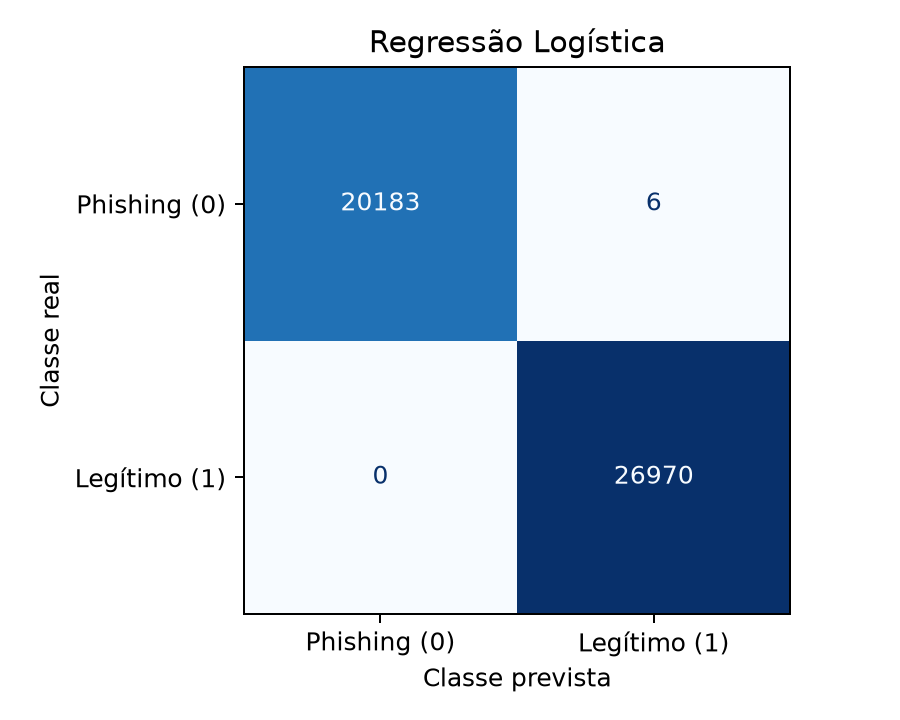

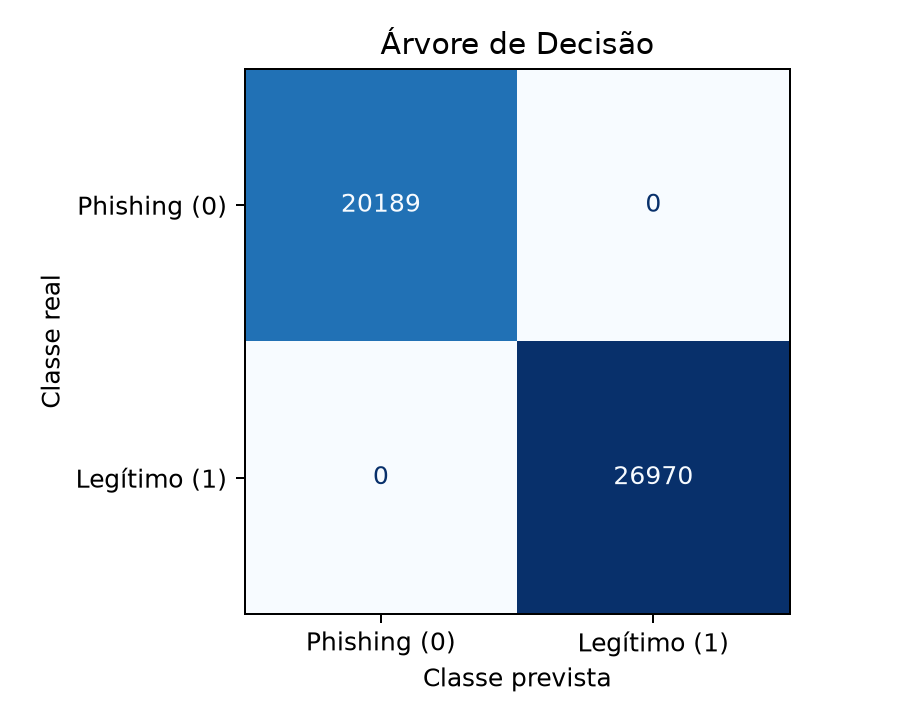

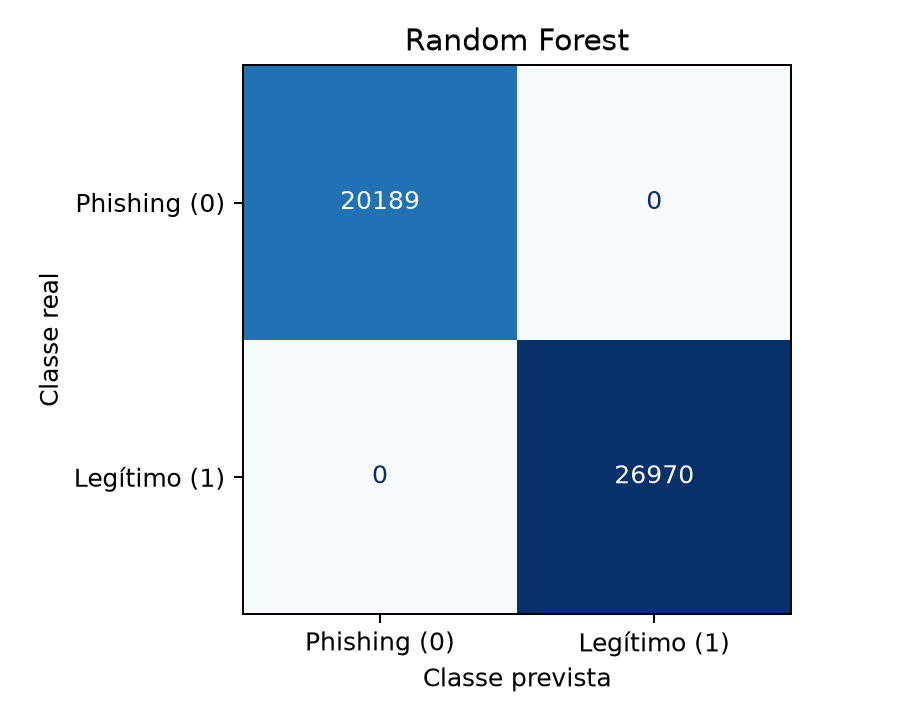

,indice_original,real,previsto
1112,56879,0,1
5025,181237,0,1
9843,7535,0,1
14442,159426,0,1
15763,168451,0,1
30594,112660,0,1


{'fonte': 'https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip',
 'licenca': 'CC BY 4.0',
 'sha256_csv': 'a236549cd369cd80bd478ff8e1779cbf44c58d5c3f79f7a51a1adbed7d06d1c6',
 'linhas': 235795,
 'colunas_csv': 56,
 'atributos_numericos': 50,
 'nulos': 0,
 'duplicados_completos': 0,
 'duplicados_atributos_numericos': 808,
 'classes': {'1': 134850, '0': 100945},
 'python': '3.12.14',
 'sklearn': '1.9.1',
 'pandas': '3.0.1',
 'numpy': '2.3.5',
 'semente': 42,
 'classe_positiva': 0,
 'dominios_sobrepostos_divisao_aleatoria': 2110,
 'arvore': {'profundidade': 4, 'folhas': 5},
 'grupos': {'treino': 189074,
  'teste': 46721,
  'sobreposicao': 0,
  'criterio': 'Domain literal em minúsculas; não agrupa eTLD+1'},
 'dominios_em_ambos_aleatorio': 2110,
 'vetores_teste_presentes_treino': 219}

In [4]:
from experimento import ROOT
for nome in ['logistica','arvore','floresta']:
    display(Image(filename=str(ROOT/f'resultados/final/matriz_{nome}.png'),width=500))
pred=pd.read_csv(ROOT/'resultados/final/previsoes_logistica.csv')
display(pred[pred.real!=pred.previsto])
display(json.loads((ROOT/'resultados/final/execucao.json').read_text(encoding='utf-8')))

## Demonstração de inferência
Dez amostras reservadas no teste. O rótulo real não é fornecido ao modelo. Essa ilustração não substitui o teste completo e não verifica URLs em tempo real.

In [5]:
from experimento import ROOT
from demonstrar import predict
import joblib
bundle=joblib.load(ROOT/'modelos/arvore.joblib')
samples=json.loads((ROOT/'resultados/final/amostras_demo.json').read_text(encoding='utf-8'))
demo=pd.DataFrame([{'registro':s['id'],'real':s['real'],'previsto':predict(s['atributos'],bundle)} for s in samples])
display(demo)
assert (demo.real==demo.previsto).all()

,registro,real,previsto
0,191560,0,0
1,185076,0,0
2,136861,0,0
3,219253,0,0
4,226985,0,0
5,173310,1,1
6,62486,1,1
7,14858,1,1
8,82943,1,1
9,72539,1,1


## Limitações e ética
Atributos pré-computados e padrões de coleta podem tornar a base muito separável. O diagnóstico por domínio não é validação temporal, externa ou por campanha. Investigar construção dos atributos, viés, falsos bloqueios e ameaças não detectadas antes de uso operacional. Leia o artigo, o guia de defesa e as pendências de entrega.